In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

Data preparation

In [2]:
df=pd.read_csv('remote_work.csv')
df['High_Performer'] = (df.Productivity_Score >= 90).astype(int)

In [3]:
print('Shape (rows, columns):', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()), '| duplicate Employee_IDs:', int(df['Employee_ID'].duplicated().sum()))


Shape (rows, columns): (1500, 31)
Missing values: 0
Duplicate rows: 0 | duplicate Employee_IDs: 0


 Descriptive statistics and visualisations

In [4]:
num_cols = ['Productivity_Score', 'Work_Hours_Per_Week', 'Meetings_Per_Week',
            'WFH_Days_Per_Week', 'Commute_Time_Minutes', 'Age']
t2 = df[num_cols].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T
t2 = t2.round(2)
print(t2.to_string())

cat_tabs = {}
for c in ['Department', 'Home_Office_Quality']:
    f = df[c].value_counts()
    tab = pd.DataFrame({'n': f, 'percent': (f / len(df) * 100).round(1)})
    print('\n', tab.to_string())
    cat_tabs[c] = tab.reset_index().rename(columns={c: 'Category', 'index': 'Category'}).to_dict('records')


                       count   mean  median    std   min    max  skew
Productivity_Score    1500.0  83.09    86.7  15.23  35.0   98.0 -0.94
Work_Hours_Per_Week   1500.0  41.73    42.0   6.04  25.0   65.0 -0.10
Meetings_Per_Week     1500.0   8.08     8.0   2.94   1.0   19.0  0.24
WFH_Days_Per_Week     1500.0   2.86     3.0   1.49   0.0    5.0 -0.38
Commute_Time_Minutes  1500.0  25.47    25.0  19.06   0.0  104.0  0.54
Age                   1500.0  35.19    35.0   8.41  22.0   65.0  0.34

                     n  percent
Department                    
Engineering       455     30.3
Sales             202     13.5
Marketing         176     11.7
Operations        137      9.1
Customer Success  120      8.0
Finance           112      7.5
HR                101      6.7
Product            81      5.4
Design             60      4.0
Data Science       56      3.7

                        n  percent
Home_Office_Quality              
Good                 595     39.7
Average              452     30.

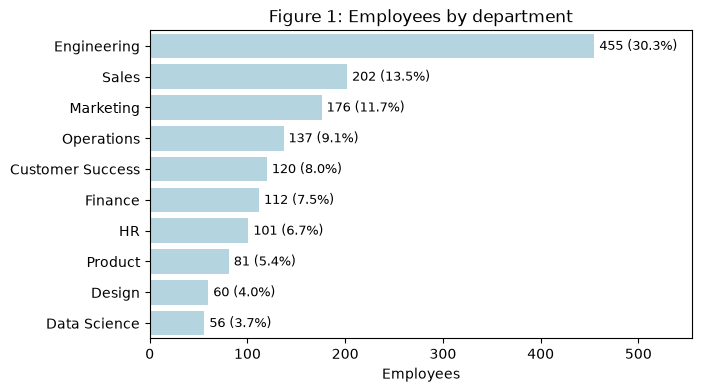

In [5]:
# Figure 1 - frequencies of Department
f = df['Department'].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=f.values, y=f.index, color='lightblue', ax=ax)
for i, v in enumerate(f.values):
    ax.text(v + 5, i, f'{v} ({v / len(df) * 100:.1f}%)', va='center', fontsize=9)
ax.set(title='Figure 1: Employees by department', xlabel='Employees', ylabel='')
ax.set_xlim(0, f.max() * 1.22)
plt.show()

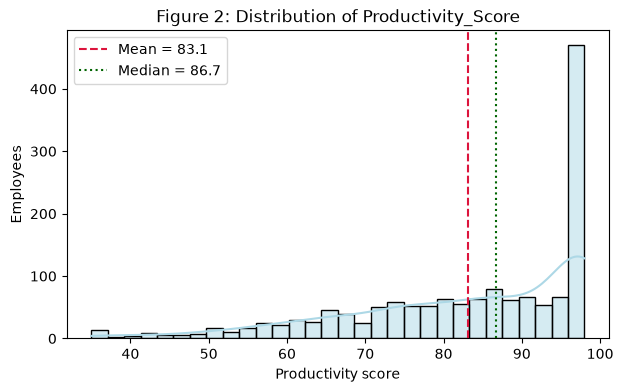

Mean (): 83.095
Median (): 86.700
Standard Deviation (): 15.227
Skewness (): -0.940
Min (): 35.0
Max (): 98.0


In [6]:
# Figure 2 - distribution of Productivity_Score
x = df['Productivity_Score']
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(x, bins=30, kde=True, color='lightblue', ax=ax)
ax.axvline(x.mean(), color='crimson', ls='--', label=f'Mean = {x.mean():.1f}')
ax.axvline(x.median(), color='darkgreen', ls=':', label=f'Median = {x.median():.1f}')
ax.set(title='Figure 2: Distribution of Productivity_Score', xlabel='Productivity score', ylabel='Employees')
ax.legend()
plt.show()
print(f"Mean (): {x.mean():.3f}")
print(f"Median (): {x.median():.3f}")
print(f"Standard Deviation (): {x.std():.3f}")
print(f"Skewness (): {stats.skew(x):.3f}")
print(f"Min (): {x.min()}")
print(f"Max (): {x.max()}")

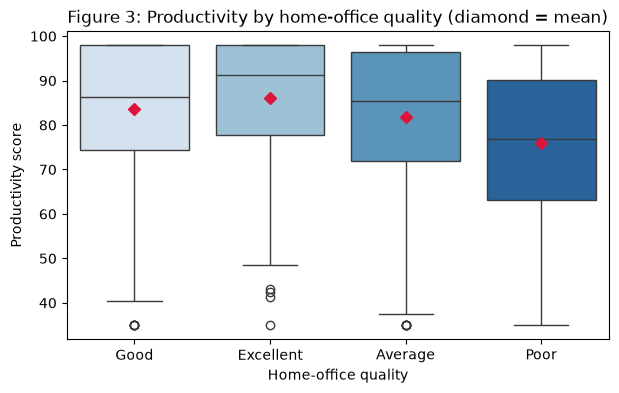

                     count   mean  median    std
Home_Office_Quality                             
Average                452  81.77   85.45  15.77
Excellent              340  86.16   91.25  13.99
Good                   595  83.72   86.40  14.61
Poor                   113  75.88   76.80  16.98
Age                     0.265518
Years_Experience        0.253481
WFH_Days_Per_Week       0.018172
Work_Hours_Per_Week    -0.030801
Task_Completion_Rate    0.884187
Quality_Score           0.917980
Innovation_Score        0.782948
Efficiency_Rating       0.838087
Meetings_Per_Week      -0.004250
Commute_Time_Minutes   -0.031447
Job_Satisfaction        0.513332
Stress_Level           -0.015355
Work_Life_Balance       0.029674
High_Performer          0.768762


In [7]:
# Figure 3 - Productivity_Score by Home_Office_Quality (group comparison)
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x='Home_Office_Quality', y='Productivity_Score', hue='Home_Office_Quality',
            palette='Blues', showmeans=True, legend=False,
            meanprops=dict(marker='D', markerfacecolor='crimson', markeredgecolor='crimson'), ax=ax)
ax.set(title='Figure 3: Productivity by home-office quality (diamond = mean)',
       xlabel='Home-office quality', ylabel='Productivity score')
plt.show()
g = df.groupby('Home_Office_Quality', observed=True)['Productivity_Score'].agg(['count', 'mean', 'median', 'std']).round(2)
print(g.to_string())

# Correlation of Productivity with other numerical variables (descriptive context)
cor = df.select_dtypes('number').corr()['Productivity_Score'].drop(['Productivity_Score'], errors='ignore')
print(cor.to_string())


Binomial distribution

In [8]:
rng=np.random.default_rng()

p_hat = 0.4313 | E[X] = np = 8.627 | Var[X] = np(1-p) = 4.906 | SD = 2.215
P(X = 8)  = 0.1726
P(X >= 10) = 0.3439
P(X <= 6)  = 0.1688
Simulated mean = 8.648, variance = 4.908; simulated P(X>=10) = 0.3473
WFH days: mean = 2.857, observed variance = 2.220, Binomial(5, 0.571) variance = 1.224


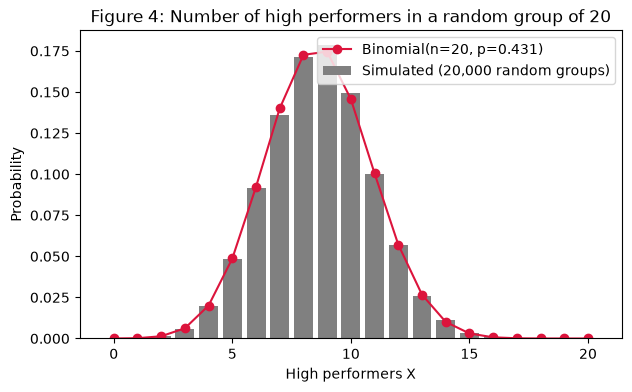

In [9]:
# Success = employee is a high performer (Productivity_Score >= 90); n = 20 employees sampled at random
p_hat = df['High_Performer'].mean()
n = 20
X = stats.binom(n, p_hat)
print(f'p_hat = {p_hat:.4f} | E[X] = np = {X.mean():.3f} | Var[X] = np(1-p) = {X.var():.3f} | SD = {X.std():.3f}')
p_eq8, p_ge10, p_le6 = X.pmf(8), X.sf(9), X.cdf(6)
print(f'P(X = 8)  = {p_eq8:.4f}')
print(f'P(X >= 10) = {p_ge10:.4f}')
print(f'P(X <= 6)  = {p_le6:.4f}')

# Empirical check: repeatedly draw 20 DIFFERENT employees (without replacement) and count high performers
sims = np.array([rng.choice(df['High_Performer'].values, size=n, replace=False).sum() for _ in range(20000)])
emp = np.bincount(sims, minlength=n + 1) / len(sims)
print(f'Simulated mean = {sims.mean():.3f}, variance = {sims.var():.3f}; simulated P(X>=10) = {(sims >= 10).mean():.4f}')

# Is a Binomial model also suitable for WFH_Days_Per_Week (n = 5 working days)?
w = df['WFH_Days_Per_Week']; p5 = w.mean() / 5
print(f'WFH days: mean = {w.mean():.3f}, observed variance = {w.var():.3f}, Binomial(5, {p5:.3f}) variance = {5*p5*(1-p5):.3f}')

k = np.arange(0, n + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(k, emp, color='gray', label='Simulated (20,000 random groups)')
ax.plot(k, X.pmf(k), 'o-', color='crimson', label=f'Binomial(n=20, p={p_hat:.3f})')
ax.set(title='Figure 4: Number of high performers in a random group of 20', xlabel='High performers X', ylabel='Probability')
ax.legend()
plt.show()

Poisson distribution

lambda_hat = 8.080, variance = 8.673, index of dispersion (var/mean) = 1.073
P(Y = 8) = 0.1395 | P(Y >= 12) = 0.1178 | P(Y <= 4) = 0.0951
Observed share: Y=8: 0.1407, Y>=12: 0.1280, Y<=4: 0.1060
Chi-square = 22.06, df = 10, p-value = 0.0148


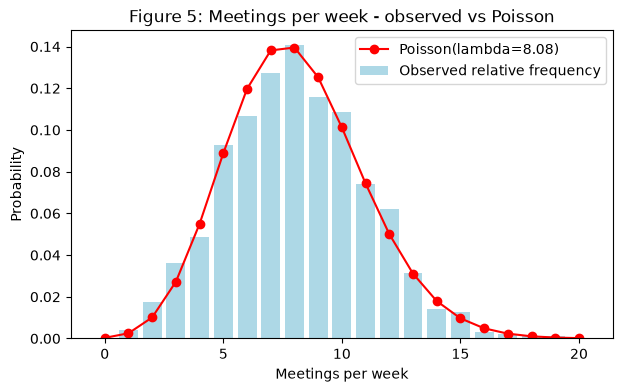

In [10]:
# Count = meetings per employee in one week (each observation has the same exposure: 1 week)
m = df['Meetings_Per_Week']
lam = m.mean(); disp = m.var() / lam
Y = stats.poisson(lam)
print(f'lambda_hat = {lam:.3f}, variance = {m.var():.3f}, index of dispersion (var/mean) = {disp:.3f}')
p8, p12, p4 = Y.pmf(8), Y.sf(11), Y.cdf(4)
print(f'P(Y = 8) = {p8:.4f} | P(Y >= 12) = {p12:.4f} | P(Y <= 4) = {p4:.4f}')
print(f'Observed share: Y=8: {(m == 8).mean():.4f}, Y>=12: {(m >= 12).mean():.4f}, Y<=4: {(m <= 4).mean():.4f}')

# Chi-square goodness of fit with pooled tails: <=3 | 4..13 (each) | >=14
obs_counts = m.value_counts().reindex(range(0, 40), fill_value=0)
O = np.array([obs_counts.loc[:3].sum()] + [obs_counts.loc[j] for j in range(4, 14)] + [obs_counts.loc[14:].sum()])
E = len(m) * np.array([Y.cdf(3)] + [Y.pmf(j) for j in range(4, 14)] + [Y.sf(13)])
chi2 = ((O - E) ** 2 / E).sum(); dof = len(O) - 1 - 1; pval = stats.chi2.sf(chi2, dof)
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {pval:.4f}')

k = np.arange(0, 21)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(k, obs_counts.reindex(k, fill_value=0).values / len(m), color='lightblue', label='Observed relative frequency')
ax.plot(k, Y.pmf(k), 'o-', color='red', label=f'Poisson(lambda={lam:.2f})')
ax.set(title='Figure 5: Meetings per week - observed vs Poisson', xlabel='Meetings per week', ylabel='Probability')
ax.legend()
plt.show()

 n_observations  max_abs_pmf_error  sample_mean
             50             0.0781       8.6800
            500             0.0137       8.1580
           5000             0.0081       8.1242
          50000             0.0032       8.0641


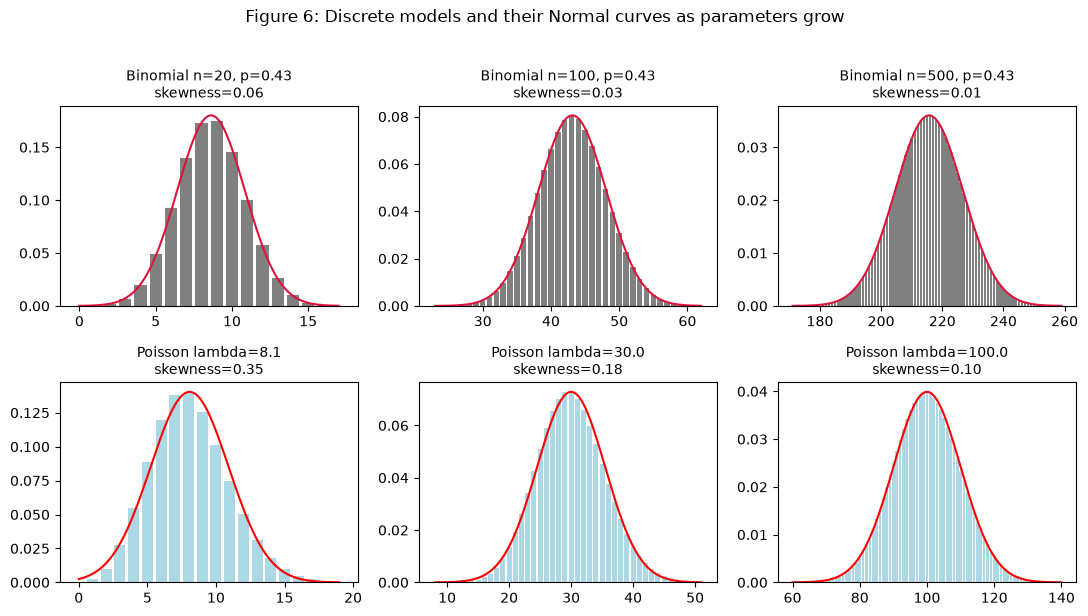

In [11]:
# (a) MORE OBSERVATIONS from the SAME Poisson model: empirical pmf converges to the theoretical pmf (law of large numbers)
k = np.arange(0, 26); theo = Y.pmf(k); rows = []
for size in [50, 500, 5000, 50000]:
    s = rng.poisson(lam, size)
    e = np.bincount(s, minlength=60)[:26] / size
    rows.append((size, float(np.abs(e - theo).max()), float(s.mean())))
tab3 = pd.DataFrame(rows, columns=['n_observations', 'max_abs_pmf_error', 'sample_mean']).round(4)
print(tab3.to_string(index=False))


# (b) LARGER PARAMETERS (n for Binomial, lambda for Poisson): the shape becomes closer to Normal (skewness -> 0)
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, nn in zip(axes[0], [20, 100, 500]):
    d = stats.binom(nn, p_hat); mu, sd = d.mean(), d.std()
    kk = np.arange(int(max(0, mu - 4 * sd)), int(mu + 4 * sd) + 1)
    ax.bar(kk, d.pmf(kk), color='gray'); xs = np.linspace(kk[0], kk[-1], 300)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), color='crimson')
    ax.set_title(f'Binomial n={nn}, p={p_hat:.2f}\nskewness={d.stats("s"):.2f}', fontsize=10)
for ax, ll in zip(axes[1], [lam, 30, 100]):
    d = stats.poisson(ll); mu, sd = d.mean(), d.std()
    kk = np.arange(int(max(0, mu - 4 * sd)), int(mu + 4 * sd) + 1)
    ax.bar(kk, d.pmf(kk), color='lightblue'); xs = np.linspace(kk[0], kk[-1], 300)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), color='red')
    ax.set_title(f'Poisson lambda={ll:.1f}\nskewness={d.stats("s"):.2f}', fontsize=10)
fig.suptitle('Figure 6: Discrete models and their Normal curves as parameters grow', y=1.02)
fig.tight_layout() 
plt.show()

Normal distribution

mean = 41.73, SD = 6.04, skewness = -0.095, excess kurtosis = -0.088
Shapiro-Wilk W = 0.9948, p = 4.24e-05
P(hours > 48): Normal = 0.1312, observed = 0.1313
P(35 <= hours <= 45): Normal = 0.6181, observed = 0.6040
95th percentile (Normal) = 51.7 hours; empirical = 51.0


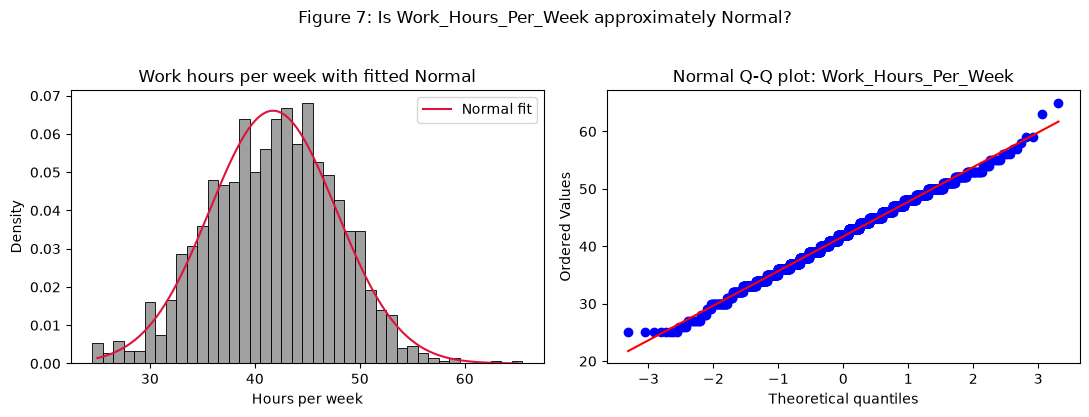

In [12]:
# Variable: Work_Hours_Per_Week (continuous-like measurement, integer hours)
wh = df['Work_Hours_Per_Week']
mu, sd = wh.mean(), wh.std(ddof=1)
sk, ku = stats.skew(wh), stats.kurtosis(wh)
sw = stats.shapiro(wh)
print(f'mean = {mu:.2f}, SD = {sd:.2f}, skewness = {sk:.3f}, excess kurtosis = {ku:.3f}')
print(f'Shapiro-Wilk W = {sw.statistic:.4f}, p = {sw.pvalue:.2e}')

# Probabilities from the fitted Normal (continuity correction 0.5 because hours are whole numbers) vs observed
p_gt48_norm = stats.norm.sf(48.5, mu, sd);  p_gt48_obs = (wh > 48).mean()
p_mid_norm = stats.norm.cdf(45.5, mu, sd) - stats.norm.cdf(34.5, mu, sd); p_mid_obs = ((wh >= 35) & (wh <= 45)).mean()
q95 = stats.norm.ppf(0.95, mu, sd)
print(f'P(hours > 48): Normal = {p_gt48_norm:.4f}, observed = {p_gt48_obs:.4f}')
print(f'P(35 <= hours <= 45): Normal = {p_mid_norm:.4f}, observed = {p_mid_obs:.4f}')
print(f'95th percentile (Normal) = {q95:.1f} hours; empirical = {wh.quantile(0.95):.1f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(wh, bins=np.arange(24.5, 66.5, 1), stat='density', color='gray', ax=axes[0])
xs = np.linspace(wh.min(), wh.max(), 300); axes[0].plot(xs, stats.norm.pdf(xs, mu, sd), color='crimson', label='Normal fit')
axes[0].set(title='Work hours per week with fitted Normal', xlabel='Hours per week'); axes[0].legend()
stats.probplot(wh, dist='norm', plot=axes[1]); axes[1].set_title('Normal Q-Q plot: Work_Hours_Per_Week')
fig.suptitle('Figure 7: Is Work_Hours_Per_Week approximately Normal?', y=1.03)
fig.tight_layout() 
plt.show()

Raw Productivity_Score: skewness = -0.940, Shapiro-Wilk p = 6.96e-33  -> Normal model rejected
Means of n=30: skewness = -0.193, Shapiro-Wilk p = 0.000
Standard error: theory sigma/sqrt(n) = 2.780, simulated = 2.764
P(sample mean of 30 employees < 80): Normal/CLT = 0.1328, simulated = 0.1301


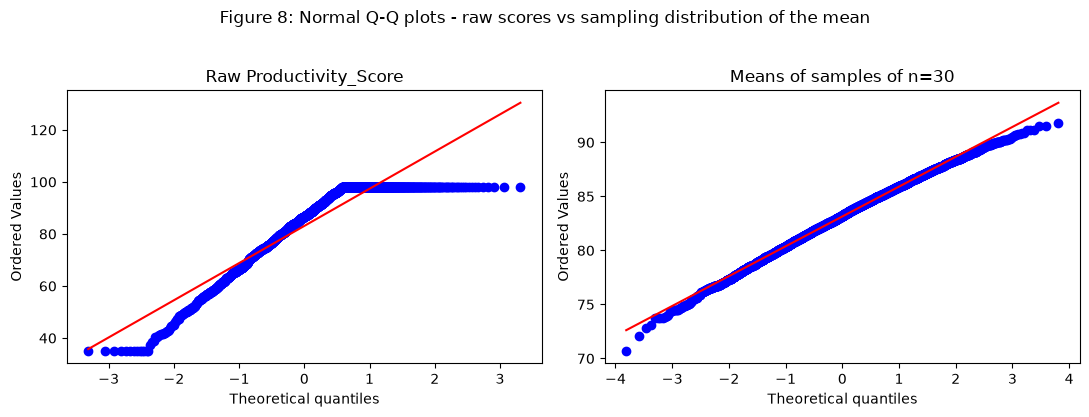

In [13]:
# Sampling distribution of the mean of Productivity_Score (raw scores are left-skewed -> Normal model for RAW data is not supported)
prod = df['Productivity_Score'].values
sw_raw = stats.shapiro(prod)
n_s = 30
means = np.array([rng.choice(prod, size=n_s, replace=True).mean() for _ in range(10000)])
se_theory = prod.std(ddof=1) / np.sqrt(n_s)
sw_means = stats.shapiro(means[:5000])
print(f'Raw Productivity_Score: skewness = {stats.skew(prod):.3f}, Shapiro-Wilk p = {sw_raw.pvalue:.2e}  -> Normal model rejected')
print(f'Means of n={n_s}: skewness = {stats.skew(means):.3f}, Shapiro-Wilk p = {sw_means.pvalue:.3f}')
print(f'Standard error: theory sigma/sqrt(n) = {se_theory:.3f}, simulated = {means.std(ddof=1):.3f}')
thr = 80
p_theory = stats.norm.cdf(thr, prod.mean(), se_theory); p_sim = (means < thr).mean()
print(f'P(sample mean of 30 employees < {thr}): Normal/CLT = {p_theory:.4f}, simulated = {p_sim:.4f}')


fig, axes = plt.subplots(1, 2, figsize=(11, 4))
stats.probplot(prod, dist='norm', plot=axes[0]); axes[0].set_title('Raw Productivity_Score')
stats.probplot(means, dist='norm', plot=axes[1]); axes[1].set_title(f'Means of samples of n={n_s}')
fig.suptitle('Figure 8: Normal Q-Q plots - raw scores vs sampling distribution of the mean', y=1.03)
fig.tight_layout() 
plt.show()

Importance, justification and Normal approximation

In [14]:
# Normal approximation with continuity correction vs exact discrete probabilities
b = stats.binom(n, p_hat); bm, bs = b.mean(), b.std()
po = stats.poisson(lam); pm, ps = po.mean(), po.std()

rows = [
    ['Binomial(20, p): P(X >= 10)', b.sf(9), stats.norm.sf(10, bm, bs), stats.norm.sf(9.5, bm, bs)],
    ['Binomial(20, p): P(X <= 6)',  b.cdf(6), stats.norm.cdf(6, bm, bs), stats.norm.cdf(6.5, bm, bs)],
    ['Poisson(lambda): P(Y >= 12)', po.sf(11), stats.norm.sf(12, pm, ps), stats.norm.sf(11.5, pm, ps)],
    ['Poisson(lambda): P(Y <= 4)',  po.cdf(4), stats.norm.cdf(4, pm, ps), stats.norm.cdf(4.5, pm, ps)],
]

t = pd.DataFrame(rows, columns=['Probability', 'Exact', 'Normal (no correction)', 'Normal (continuity corr.)']).round(4)
print(t.to_string(index=False))
print()

# WFH days from the dataframe
wfh_mean = df['WFH_Days_Per_Week'].mean()

# 2. Rule of thumb and WFH calculations
print(f'Binomial rule of thumb: np = {n * p_hat:.2f}, n(1-p) = {n * (1 - p_hat):.2f} (both >= 5?)')
print(f'Poisson: lambda = {lam:.2f}; Binomial(5, p) for WFH days: np = {wfh_mean:.2f}, n(1-p) = {5 - wfh_mean:.2f}')

                Probability  Exact  Normal (no correction)  Normal (continuity corr.)
Binomial(20, p): P(X >= 10) 0.3439                  0.2676                     0.3467
 Binomial(20, p): P(X <= 6) 0.1688                  0.1178                     0.1685
Poisson(lambda): P(Y >= 12) 0.1178                  0.0839                     0.1145
 Poisson(lambda): P(Y <= 4) 0.0951                  0.0756                     0.1039

Binomial rule of thumb: np = 8.63, n(1-p) = 11.37 (both >= 5?)
Poisson: lambda = 8.08; Binomial(5, p) for WFH days: np = 2.86, n(1-p) = 2.14
